# Modelo 1 · Próximo movimiento de la competencia
## Notebook 2 · Parte 1: agrupar las series según cómo se mueve su precio

**La pregunta.** No todas las series (producto × comercio) se comportan igual: unas casi nunca cambian de precio, otras viven en oferta, otras solo bajan en las temporadas y otras siguen lo que hace otro comercio. Si Pycca sabe a qué tipo pertenece cada serie, puede vigilar cada una de forma distinta y predecir mejor.

**La tarea.** Agrupar las 3.616 series con un método **no supervisado** (K-means, jerárquico, DBSCAN, mezclas gaussianas…). Nadie les dice cuántos grupos hay ni cuáles son: eso es parte del reto.

**Cómo se evalúa.** El simulador le dio a cada serie un perfil de comportamiento que no viene en los datos. Pycca compara los grupos entregados con esos perfiles usando el **ARI** (índice de Rand ajustado): 0 es como agrupar al azar y 1 es recuperarlos exactamente; no importa cómo se llamen los grupos.

**Punto de partida.** `datos/tabla_series.csv` trae una fila por serie, con su comportamiento en el entrenamiento (2023–2024). Se pueden calcular otras variables desde `precios_diarios.parquet`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings('ignore')
RAIZ = Path('..') if Path('../variables.py').exists() else Path('.')     # repo (notebooks/) o paquete de ESPOL
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, '.')
import estilo; estilo.aplicar()
from estilo import AZUL, NARANJA, AQUA, TINTA2, GRIS, pie
DATOS = RAIZ / 'datos'
pd.set_option('display.width', 160)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

### 1. La tabla de series

In [2]:
t = pd.read_csv(DATOS / 'tabla_series.csv')
VARS = ['cambios_por_mes', 'parte_dias_en_oferta', 'ofertas_por_año', 'dias_por_oferta', 'descuento_medio_oferta',
        'bajas_5pct_por_año', 'parte_bajas_en_evento', 'parte_dias_sin_stock']
print(f'{len(t):,} series | {t.comercio_id.nunique()} comercios | {t.producto_id.nunique():,} productos')
t.head()

3,616 series | 13 comercios | 1,500 productos


,comercio_id,producto_id,division,precio_mediano,cambios_por_mes,parte_dias_en_oferta,ofertas_por_año,dias_por_oferta,descuento_medio_oferta,bajas_5pct_por_año,parte_bajas_en_evento,parte_dias_sin_stock
0,C01,P00003,PAPELERIA & REGALERIA,11.94,1.272,0.1751,5.50,11.64,0.3744,5.00,0.4000,0.5466
1,C01,P00004,ELECTRO,121.60,1.642,0.1888,10.01,6.90,0.2056,8.51,0.2353,0.4986
2,C01,P00018,PAPELERIA & REGALERIA,3.09,0.575,0.0944,3.50,9.86,0.3329,2.50,0.6000,0.5480
3,C01,P00022,ELECTRO,108.74,0.164,0.0109,0.50,8.00,0.1665,0.50,0.0000,0.5841
4,C01,P00028,INFANTIL,19.62,0.698,0.0848,3.00,10.33,0.2432,3.00,0.3333,0.5546


In [3]:
t[VARS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
cambios_por_mes,3616.0,0.975,1.009,0.000,0.328,0.616,1.272,6.279
parte_dias_en_oferta,3616.0,0.127,0.143,0.000,0.029,0.077,0.176,0.759
ofertas_por_año,3616.0,5.002,6.146,0.000,1.000,3.000,6.500,37.530
dias_por_oferta,3616.0,9.167,5.059,0.000,6.960,8.975,11.722,26.000
descuento_medio_oferta,3242.0,0.249,0.143,0.028,0.152,0.201,0.293,0.769
bajas_5pct_por_año,3616.0,4.443,4.845,0.000,1.000,3.000,6.000,30.020
parte_bajas_en_evento,3380.0,0.421,0.279,0.000,0.250,0.400,0.571,1.000
parte_dias_sin_stock,3616.0,0.103,0.191,0.000,0.000,0.000,0.098,0.644


### 2. Cómo se reparten las series

Ofertas por año de cada serie. Hay series que casi nunca entran en oferta y otras que entran más de una vez al mes: ahí ya se ve que no son todas iguales.

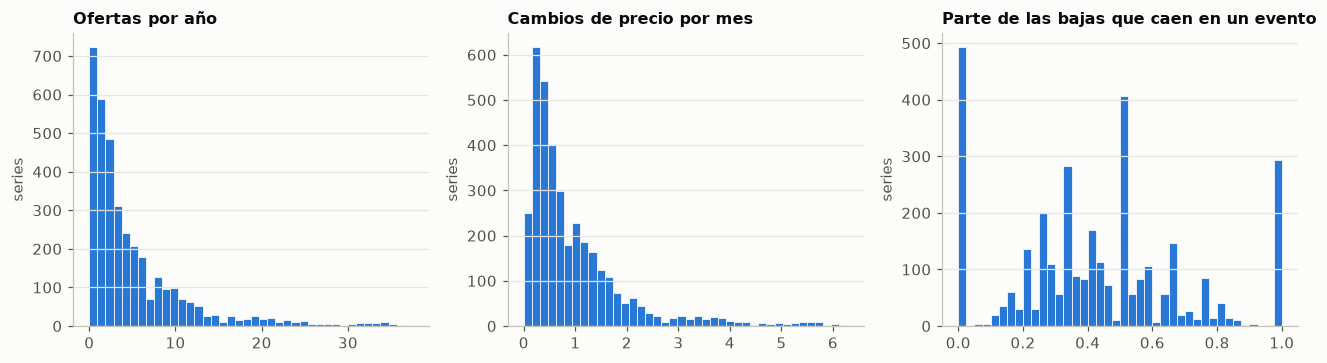

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, c, tit in zip(axs, ['ofertas_por_año', 'cambios_por_mes', 'parte_bajas_en_evento'],
                      ['Ofertas por año', 'Cambios de precio por mes', 'Parte de las bajas que caen en un evento']):
    ax.hist(t[c].dropna(), bins=40, color=AZUL, edgecolor='white', linewidth=0.5)
    ax.set_title(tit, fontsize=10.5); ax.set_ylabel('series'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

### 3. Baseline: K-means con las variables tal cual

Se estandarizan las variables (media 0, desviación 1) y se prueba de 2 a 8 grupos. El **coeficiente de silueta** mide qué tan separados quedan los grupos (más alto es mejor) y la **inercia** (codo) cuánto se reduce la distancia dentro de los grupos.

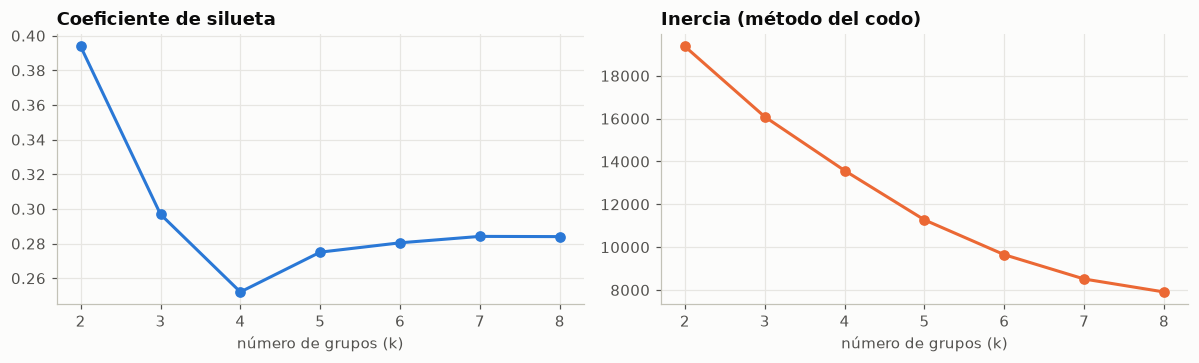

k elegido por la silueta: 2 | series por grupo: {0: 3053, 1: 563}


In [5]:
X = t[VARS].fillna(t[VARS].median())          # series sin ofertas o sin bajas: valor típico
Z = StandardScaler().fit_transform(X)
ks = range(2, 9); sil, ine = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=7).fit(Z)
    sil.append(silhouette_score(Z, km.labels_)); ine.append(km.inertia_)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(ks, sil, marker='o', color=AZUL); axs[0].set_title('Coeficiente de silueta'); axs[0].set_xlabel('número de grupos (k)')
axs[1].plot(ks, ine, marker='o', color=NARANJA); axs[1].set_title('Inercia (método del codo)'); axs[1].set_xlabel('número de grupos (k)')
plt.tight_layout(); plt.show()
k = list(ks)[int(np.argmax(sil))]
t['grupo'] = KMeans(k, n_init=10, random_state=7).fit_predict(Z)
t[['comercio_id', 'producto_id', 'grupo']].to_csv(RAIZ / 'grupos_baseline.csv', index=False)
print('k elegido por la silueta:', k, '| series por grupo:', t.grupo.value_counts().sort_index().to_dict())

### 4. Cómo es cada grupo

Promedio de cada variable en cada grupo, en desviaciones frente al total (rojo: más alto que el promedio; azul: más bajo).

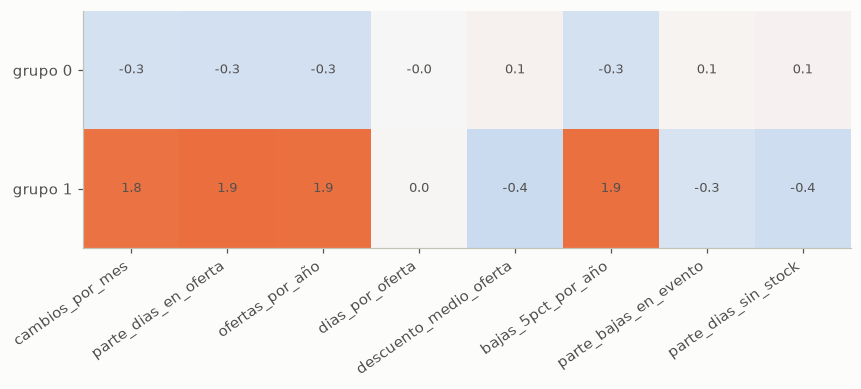

grupo,0,1
cambios_por_mes,0.634,2.824
parte_dias_en_oferta,0.078,0.397
ofertas_por_año,2.881,16.508
dias_por_oferta,9.143,9.300
descuento_medio_oferta,0.262,0.184
bajas_5pct_por_año,2.777,13.473
parte_bajas_en_evento,0.438,0.338
parte_dias_sin_stock,0.117,0.028


In [6]:
perfil = pd.DataFrame(Z, columns=VARS).groupby(t.grupo).mean()
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('div', [AZUL, '#f7f7f7', NARANJA])
fig, ax = plt.subplots(figsize=(9, 0.6 * len(perfil) + 1.6))
im = ax.imshow(perfil.values, cmap=cmap, vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(VARS)), VARS, rotation=35, ha='right'); ax.set_yticks(range(len(perfil)), [f'grupo {g}' for g in perfil.index]); ax.grid(False)
for i in range(perfil.shape[0]):
    for j in range(perfil.shape[1]):
        ax.text(j, i, f'{perfil.values[i, j]:.1f}', ha='center', va='center', fontsize=8.5, color=TINTA2)
plt.show()
t.groupby('grupo')[VARS].mean().round(3).T

### 5. Mapa de las series en dos dimensiones (PCA)

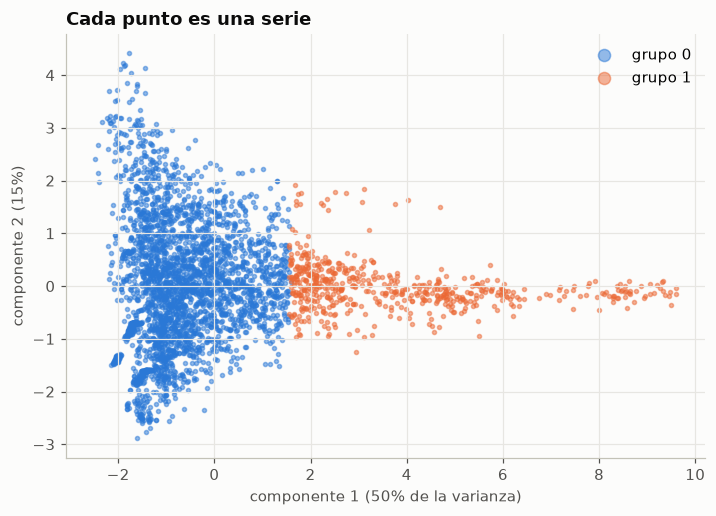

In [7]:
pc = PCA(2, random_state=7).fit(Z); P = pc.transform(Z)
fig, ax = plt.subplots(figsize=(7.5, 5))
for g, col in zip(sorted(t.grupo.unique()), estilo.SERIES):
    m = t.grupo.values == g
    ax.scatter(P[m, 0], P[m, 1], s=7, alpha=0.5, color=col, label=f'grupo {g}')
ax.set_xlabel(f'componente 1 ({pc.explained_variance_ratio_[0]:.0%} de la varianza)'); ax.set_ylabel(f'componente 2 ({pc.explained_variance_ratio_[1]:.0%})')
ax.legend(markerscale=3); ax.set_title('Cada punto es una serie')
plt.show()

### 6. La trampa: ¿encontramos tipos de serie o encontramos comercios?

Cada comercio tiene su propio nivel: hay comercios que siempre muestran un precio tachado y otros que casi no hacen ofertas. Si los grupos se parecen mucho a los comercios, el modelo está agrupando **comercios**, no comportamientos. Esta tabla muestra qué parte de las series de cada comercio cayó en cada grupo.

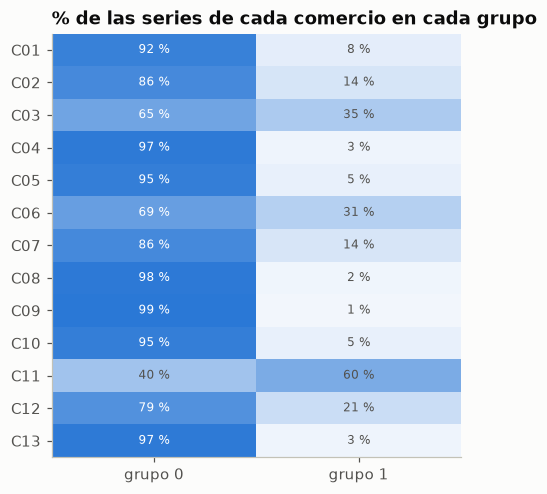

In [8]:
ct = pd.crosstab(t.comercio_id, t.grupo, normalize='index') * 100
fig, ax = plt.subplots(figsize=(0.9 * ct.shape[1] + 3, 5))
im = ax.imshow(ct.values, cmap=LinearSegmentedColormap.from_list('azul', ['#f3f7fd', AZUL]), vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(ct.shape[1]), [f'grupo {g}' for g in ct.columns]); ax.set_yticks(range(len(ct)), ct.index); ax.grid(False)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f'{ct.values[i, j]:.0f} %', ha='center', va='center', fontsize=8, color='white' if ct.values[i, j] > 60 else TINTA2)
ax.set_title('% de las series de cada comercio en cada grupo')
plt.show()

## Resumen y entrega de la parte 1

- El baseline (K-means con las variables tal cual y k elegido por la silueta) es el punto de partida. En los perfiles ocultos obtiene un **ARI de 0,09**: casi no los encuentra.
- **Pistas para mejorar:** transformar las variables muy sesgadas (logaritmo), comparar cada serie con las demás **de su mismo comercio**, probar otro número de grupos y otros métodos, y crear variables nuevas desde los precios diarios (por ejemplo, ¿la serie baja pocos días después de que otro comercio bajó el mismo producto?).
- **Formato de entrega:** un CSV con `comercio_id`, `producto_id` y `grupo` para las 3.616 series (como `grupos_baseline.csv`), más una descripción en palabras de cada grupo.

Siguiente: **03_clasificacion.ipynb**, la parte 2: predecir la baja. Ahí se puede usar el grupo como una variable más.